In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt

from scipy import stats

In [2]:
returns = pd.read_csv(
    "data/processed/returns.csv",
    index_col=0,
    parse_dates=True
)

returns.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.018225,0.015586,0.014965,-0.137818
2015-01-06,-0.009463,0.017857,0.011334,0.041796
2015-01-07,0.012384,-0.001977,-0.005909,0.028073
2015-01-08,0.017589,-0.013332,-0.004217,-0.038046
2015-01-09,-0.008046,0.010893,0.011321,0.024607


In [3]:
TRAIN_END = "2022-12-31"
TEST_START = "2023-01-01"

train_returns = returns.loc[:TRAIN_END].copy()
test_returns = returns.loc[TEST_START:].copy()

print("Training:")
print(train_returns.index.min())
print(train_returns.index.max())
print(len(train_returns))

print("\nTesting:")
print(test_returns.index.min())
print(test_returns.index.max())
print(len(test_returns))

Training:
2015-01-05 00:00:00
2022-12-30 00:00:00
2013

Testing:
2023-01-03 00:00:00
2026-09-30 00:00:00
939


In [4]:
ASSETS = [
    "SPY",
    "TLT",
    "GLD",
    "BTC-USD"
]

weights = np.array([
    0.25,
    0.25,
    0.25,
    0.25
])

print("Weights sum:", weights.sum())

Weights sum: 1.0


In [5]:
WAVELET = "db4"
LEVEL = 6

In [6]:
def reconstruct_component(
    series,
    wavelet="db4",
    level=6,
    component_level=1
):

    values = np.asarray(
        series,
        dtype=float
    )

    coeffs = pywt.wavedec(
        values,
        wavelet=wavelet,
        level=level,
        mode="symmetric"
    )

    selected = [
        np.zeros_like(c)
        for c in coeffs
    ]

    index = (
        level
        -
        component_level
        +
        1
    )

    selected[index] = coeffs[index]

    reconstructed = pywt.waverec(
        selected,
        wavelet=wavelet,
        mode="symmetric"
    )

    return reconstructed[:len(values)]

In [7]:
def create_horizons(df):

    components = {}

    for asset in df.columns:

        asset_components = {}

        for component_level in range(1, 7):

            asset_components[
                f"D{component_level}"
            ] = reconstruct_component(
                df[asset],
                wavelet=WAVELET,
                level=LEVEL,
                component_level=component_level
            )

        components[asset] = pd.DataFrame(
            asset_components,
            index=df.index
        )


    short = pd.DataFrame(
        index=df.index
    )

    medium = pd.DataFrame(
        index=df.index
    )

    long = pd.DataFrame(
        index=df.index
    )


    for asset in df.columns:

        short[asset] = (
            components[asset]["D1"]
            +
            components[asset]["D2"]
        )

        medium[asset] = (
            components[asset]["D3"]
            +
            components[asset]["D4"]
        )

        long[asset] = (
            components[asset]["D5"]
            +
            components[asset]["D6"]
        )

    return short, medium, long

In [8]:
train_short, train_medium, train_long = (
    create_horizons(
        train_returns
    )
)

print(train_short.shape)
print(train_medium.shape)
print(train_long.shape)

(2013, 4)
(2013, 4)
(2013, 4)


In [9]:
test_short, test_medium, test_long = (
    create_horizons(
        test_returns
    )
)

print(test_short.shape)
print(test_medium.shape)
print(test_long.shape)

(939, 4)
(939, 4)
(939, 4)


In [10]:
train_spy_vol = (
    train_returns["SPY"]
    .rolling(20)
    .std()
    * np.sqrt(252)
).shift(1)

In [11]:
stress_threshold = (
    train_spy_vol
    .dropna()
    .quantile(0.75)
)

print(
    "Training stress threshold:",
    stress_threshold
)

Training stress threshold: 0.19868482797496093


In [12]:
def create_regimes(
    returns_df,
    threshold
):

    vol = (
        returns_df["SPY"]
        .rolling(20)
        .std()
        * np.sqrt(252)
    ).shift(1)

    regimes = pd.DataFrame(
        index=returns_df.index
    )

    regimes["Volatility"] = vol

    regimes["Regime"] = np.where(
        vol > threshold,
        "Stress",
        "Normal"
    )

    regimes = regimes.dropna()

    return regimes

In [13]:
train_regimes = create_regimes(
    train_returns,
    stress_threshold
)

train_regimes.head()

,Volatility,Regime
2015-02-03,0.175336,Normal
2015-02-04,0.170624,Normal
2015-02-05,0.167277,Normal
2015-02-06,0.165370,Normal
2015-02-09,0.153540,Normal


In [14]:
test_context = pd.concat(
    [
        train_returns.tail(20),
        test_returns
    ]
)

In [15]:
test_regimes_full = create_regimes(
    test_context,
    stress_threshold
)

In [16]:
test_regimes = (
    test_regimes_full
    .loc[TEST_START:]
)

test_regimes.head()

,Volatility,Regime
2023-01-03,0.184928,Normal
2023-01-04,0.184858,Normal
2023-01-05,0.179604,Normal
2023-01-06,0.177052,Normal
2023-01-09,0.196961,Normal


In [17]:
print("Training regimes:")
print(
    train_regimes[
        "Regime"
    ].value_counts()
)

print("\nTesting regimes:")
print(
    test_regimes[
        "Regime"
    ].value_counts()
)

Training regimes:
Regime
Normal    1495
Stress     498
Name: count, dtype: int64

Testing regimes:
Regime
Normal    880
Stress     59
Name: count, dtype: int64


In [18]:
train_short_regime = train_short.join(
    train_regimes["Regime"],
    how="inner"
)

train_medium_regime = train_medium.join(
    train_regimes["Regime"],
    how="inner"
)

train_long_regime = train_long.join(
    train_regimes["Regime"],
    how="inner"
)

In [19]:
test_short_regime = test_short.join(
    test_regimes["Regime"],
    how="inner"
)

test_medium_regime = test_medium.join(
    test_regimes["Regime"],
    how="inner"
)

test_long_regime = test_long.join(
    test_regimes["Regime"],
    how="inner"
)

In [20]:
train_datasets = {

    "Short_Normal":
        train_short_regime[
            train_short_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Short_Stress":
        train_short_regime[
            train_short_regime["Regime"]
            ==
            "Stress"
        ][ASSETS],

    "Medium_Normal":
        train_medium_regime[
            train_medium_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Medium_Stress":
        train_medium_regime[
            train_medium_regime["Regime"]
            ==
            "Stress"
        ][ASSETS],

    "Long_Normal":
        train_long_regime[
            train_long_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Long_Stress":
        train_long_regime[
            train_long_regime["Regime"]
            ==
            "Stress"
        ][ASSETS]
}

In [21]:
test_datasets = {

    "Short_Normal":
        test_short_regime[
            test_short_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Short_Stress":
        test_short_regime[
            test_short_regime["Regime"]
            ==
            "Stress"
        ][ASSETS],

    "Medium_Normal":
        test_medium_regime[
            test_medium_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Medium_Stress":
        test_medium_regime[
            test_medium_regime["Regime"]
            ==
            "Stress"
        ][ASSETS],

    "Long_Normal":
        test_long_regime[
            test_long_regime["Regime"]
            ==
            "Normal"
        ][ASSETS],

    "Long_Stress":
        test_long_regime[
            test_long_regime["Regime"]
            ==
            "Stress"
        ][ASSETS]
}

In [22]:
for name in train_datasets:

    print(
        name,
        "| Train:",
        len(train_datasets[name]),
        "| Test:",
        len(test_datasets[name])
    )

Short_Normal | Train: 1495 | Test: 880
Short_Stress | Train: 498 | Test: 59
Medium_Normal | Train: 1495 | Test: 880
Medium_Stress | Train: 498 | Test: 59
Long_Normal | Train: 1495 | Test: 880
Long_Stress | Train: 498 | Test: 59


In [23]:
def kendall_correlation_matrix(df):

    d = df.shape[1]

    R = np.eye(d)

    for i in range(d):

        for j in range(i + 1, d):

            tau, _ = stats.kendalltau(
                df.iloc[:, i],
                df.iloc[:, j]
            )

            rho = np.sin(
                np.pi * tau / 2
            )

            R[i, j] = rho
            R[j, i] = rho

    return R

In [24]:
def nearest_positive_definite_correlation(R):

    eigenvalues, eigenvectors = (
        np.linalg.eigh(R)
    )

    eigenvalues = np.clip(
        eigenvalues,
        1e-6,
        None
    )

    R_pd = (
        eigenvectors
        @ np.diag(eigenvalues)
        @ eigenvectors.T
    )

    scale = np.sqrt(
        np.diag(R_pd)
    )

    R_corr = (
        R_pd
        /
        np.outer(scale, scale)
    )

    np.fill_diagonal(
        R_corr,
        1.0
    )

    return R_corr

In [25]:
benchmark_R = kendall_correlation_matrix(
    train_returns[ASSETS]
)

benchmark_R = (
    nearest_positive_definite_correlation(
        benchmark_R
    )
)

pd.DataFrame(
    benchmark_R,
    index=ASSETS,
    columns=ASSETS
)

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.267926,-0.019250,0.164525
TLT,-0.267926,1.000000,0.355552,-0.020981
GLD,-0.019250,0.355552,1.000000,0.093311
BTC-USD,0.164525,-0.020981,0.093311,1.000000


In [26]:
def simulate_gaussian_copula(
    R,
    n_simulations=20000,
    seed=42
):

    rng = np.random.default_rng(seed)

    z = rng.multivariate_normal(
        mean=np.zeros(
            R.shape[0]
        ),
        cov=R,
        size=n_simulations
    )

    return stats.norm.cdf(z)

In [27]:
def inverse_empirical_marginals(
    U,
    historical_df
):

    simulated_returns = np.zeros_like(
        U
    )

    for j, asset in enumerate(
        historical_df.columns
    ):

        simulated_returns[:, j] = (
            np.quantile(
                historical_df[
                    asset
                ].values,
                U[:, j]
            )
        )

    return simulated_returns

In [28]:
def pseudo_observation_matrix(df):

    n = len(df)

    U = np.zeros(
        df.shape
    )

    for j, column in enumerate(
        df.columns
    ):

        ranks = stats.rankdata(
            df[column],
            method="average"
        )

        U[:, j] = (
            ranks
            /
            (n + 1.0)
        )

    return U

In [29]:
def multivariate_t_copula_loglik(
    U,
    R,
    nu
):

    X = stats.t.ppf(
        U,
        df=nu
    )

    joint = (
        stats.multivariate_t.logpdf(
            X,
            loc=np.zeros(
                U.shape[1]
            ),
            shape=R,
            df=nu
        )
    )

    marginal = np.sum(
        stats.t.logpdf(
            X,
            df=nu
        ),
        axis=1
    )

    return np.sum(
        joint - marginal
    )

In [30]:
def estimate_t_nu(
    df,
    R
):

    U = pseudo_observation_matrix(
        df
    )

    results = []

    for nu in range(3, 31):

        loglik = (
            multivariate_t_copula_loglik(
                U,
                R,
                nu
            )
        )

        results.append({
            "nu": nu,
            "loglik": loglik
        })

    results = pd.DataFrame(
        results
    )

    best = results.loc[
        results["loglik"].idxmax()
    ]

    return float(best["nu"])

In [31]:
def simulate_t_copula(
    R,
    nu,
    n_simulations=20000,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    X = stats.multivariate_t.rvs(
        loc=np.zeros(
            R.shape[0]
        ),
        shape=R,
        df=nu,
        size=n_simulations,
        random_state=rng
    )

    U = stats.t.cdf(
        X,
        df=nu
    )

    return U

In [32]:
def calculate_risk(returns):

    returns = np.asarray(
        returns
    )

    q05 = np.quantile(
        returns,
        0.05
    )

    q01 = np.quantile(
        returns,
        0.01
    )

    q025 = np.quantile(
        returns,
        0.025
    )

    var95 = -q05
    var99 = -q01

    es975 = -returns[
        returns <= q025
    ].mean()

    return {
        "VaR_95": var95,
        "VaR_99": var99,
        "ES_97.5": es975
    }

In [33]:
benchmark_R

array([[ 1.        , -0.26792637, -0.01925036,  0.16452452],
       [-0.26792637,  1.        ,  0.35555183, -0.02098057],
       [-0.01925036,  0.35555183,  1.        ,  0.09331053],
       [ 0.16452452, -0.02098057,  0.09331053,  1.        ]])

In [34]:
def benchmark_risk(
    train_df,
    benchmark_R,
    weights,
    n_simulations=20000,
    seed=42
):

    U = simulate_gaussian_copula(
        benchmark_R,
        n_simulations,
        seed
    )

    simulated = inverse_empirical_marginals(
        U,
        train_df
    )

    portfolio = (
        simulated @ weights
    )

    return calculate_risk(
        portfolio
    )

In [35]:
def proposed_risk(
    train_df,
    weights,
    n_simulations=20000,
    seed=42
):

    R = kendall_correlation_matrix(
        train_df
    )

    R = nearest_positive_definite_correlation(
        R
    )

    nu = estimate_t_nu(
        train_df,
        R
    )

    U = simulate_t_copula(
        R,
        nu,
        n_simulations,
        seed
    )

    simulated = inverse_empirical_marginals(
        U,
        train_df
    )

    portfolio = (
        simulated @ weights
    )

    risk = calculate_risk(
        portfolio
    )

    risk["nu"] = nu

    return risk

In [36]:
example_name = "Short_Normal"

benchmark_example = benchmark_risk(
    train_datasets[example_name],
    benchmark_R,
    weights
)

proposed_example = proposed_risk(
    train_datasets[example_name],
    weights
)

print("Benchmark:")
print(benchmark_example)

print("\nProposed:")
print(proposed_example)

Benchmark:
{'VaR_95': np.float64(0.01689463633241637), 'VaR_99': np.float64(0.02848555663955636), 'ES_97.5': np.float64(0.029063825115733393)}

Proposed:
{'VaR_95': np.float64(0.016514274584534458), 'VaR_99': np.float64(0.02882652615742898), 'ES_97.5': np.float64(0.02957564074395792), 'nu': 13.0}


In [37]:
actual_test_portfolios = {}

for name, df in test_datasets.items():

    actual_test_portfolios[name] = (
        df[ASSETS].values
        @ weights
    )

In [38]:
def count_var_violations(
    actual_returns,
    var_value
):

    actual_returns = np.asarray(
        actual_returns
    )

    violations = (
        actual_returns
        <
        -var_value
    )

    return {
        "Violations": int(
            violations.sum()
        ),

        "Observations": int(
            len(actual_returns)
        ),

        "Violation_Rate": (
            violations.mean()
        )
    }

In [39]:
oos_results = []

for name in train_datasets:

    print(
        "Processing:",
        name
    )

    train_df = train_datasets[
        name
    ]

    actual_test = (
        actual_test_portfolios[
            name
        ]
    )


    # -------------------------
    # Benchmark
    # -------------------------

    benchmark = benchmark_risk(
        train_df,
        benchmark_R,
        weights,
        n_simulations=20000,
        seed=42
    )

    benchmark_95 = (
        count_var_violations(
            actual_test,
            benchmark["VaR_95"]
        )
    )

    benchmark_99 = (
        count_var_violations(
            actual_test,
            benchmark["VaR_99"]
        )
    )

    oos_results.append({
        "Dataset": name,
        "Model": "Single-Dependence Gaussian",
        "VaR_95": benchmark["VaR_95"],
        "VaR_99": benchmark["VaR_99"],
        "ES_97.5": benchmark["ES_97.5"],
        "Violations_95": benchmark_95[
            "Violations"
        ],
        "Violation_Rate_95": benchmark_95[
            "Violation_Rate"
        ],
        "Violations_99": benchmark_99[
            "Violations"
        ],
        "Violation_Rate_99": benchmark_99[
            "Violation_Rate"
        ],
        "Test_N": len(actual_test),
        "nu": np.nan
    })


    # -------------------------
    # Proposed
    # -------------------------

    proposed = proposed_risk(
        train_df,
        weights,
        n_simulations=20000,
        seed=42
    )

    proposed_95 = (
        count_var_violations(
            actual_test,
            proposed["VaR_95"]
        )
    )

    proposed_99 = (
        count_var_violations(
            actual_test,
            proposed["VaR_99"]
        )
    )

    oos_results.append({
        "Dataset": name,
        "Model": "Regime-Horizon Student-t",
        "VaR_95": proposed["VaR_95"],
        "VaR_99": proposed["VaR_99"],
        "ES_97.5": proposed["ES_97.5"],
        "Violations_95": proposed_95[
            "Violations"
        ],
        "Violation_Rate_95": proposed_95[
            "Violation_Rate"
        ],
        "Violations_99": proposed_99[
            "Violations"
        ],
        "Violation_Rate_99": proposed_99[
            "Violation_Rate"
        ],
        "Test_N": len(actual_test),
        "nu": proposed["nu"]
    })

Processing: Short_Normal


Processing: Short_Stress


Processing: Medium_Normal


Processing: Medium_Stress


Processing: Long_Normal


Processing: Long_Stress


In [40]:
oos_results = pd.DataFrame(
    oos_results
)

oos_results

,Dataset,Model,VaR_95,VaR_99,ES_97.5,Violations_95,Violation_Rate_95,Violations_99,Violation_Rate_99,Test_N,nu
0,Short_Normal,Single-Dependence Gaussian,0.016895,0.028486,0.029064,19,0.021591,1,0.001136,880,NaN
1,Short_Normal,Regime-Horizon Student-t,0.016514,0.028827,0.029576,21,0.023864,1,0.001136,880,13.0
2,Short_Stress,Single-Dependence Gaussian,0.018361,0.031075,0.032613,1,0.016949,0,0.000000,59,NaN
3,Short_Stress,Regime-Horizon Student-t,0.018423,0.033896,0.037193,1,0.016949,0,0.000000,59,5.0
4,Medium_Normal,Single-Dependence Gaussian,0.008638,0.013508,0.013279,18,0.020455,2,0.002273,880,NaN
5,Medium_Normal,Regime-Horizon Student-t,0.008171,0.012676,0.012875,22,0.025000,2,0.002273,880,12.0
6,Medium_Stress,Single-Dependence Gaussian,0.009827,0.016954,0.016855,2,0.033898,0,0.000000,59,NaN
7,Medium_Stress,Regime-Horizon Student-t,0.010401,0.018924,0.019060,2,0.033898,0,0.000000,59,4.0
8,Long_Normal,Single-Dependence Gaussian,0.004492,0.006227,0.006252,12,0.013636,4,0.004545,880,NaN
9,Long_Normal,Regime-Horizon Student-t,0.004534,0.006297,0.006408,12,0.013636,3,0.003409,880,10.0


In [41]:
oos_results[
    "Expected_Rate_95"
] = 0.05

oos_results[
    "Expected_Rate_99"
] = 0.01

In [42]:
oos_results[
    "Violation_Error_95"
] = (
    oos_results[
        "Violation_Rate_95"
    ]
    -
    0.05
)

oos_results[
    "Violation_Error_99"
] = (
    oos_results[
        "Violation_Rate_99"
    ]
    -
    0.01
)

In [43]:
oos_results[
    "Abs_Calibration_Error_95"
] = (
    oos_results[
        "Violation_Error_95"
    ]
    .abs()
)

oos_results[
    "Abs_Calibration_Error_99"
] = (
    oos_results[
        "Violation_Error_99"
    ]
    .abs()
)

In [44]:
display_results = (
    oos_results.copy()
)

percentage_columns = [
    "VaR_95",
    "VaR_99",
    "ES_97.5",
    "Violation_Rate_95",
    "Violation_Rate_99",
    "Abs_Calibration_Error_95",
    "Abs_Calibration_Error_99"
]

for col in percentage_columns:

    display_results[col] = (
        display_results[col]
        * 100
    )

display_results.round(3)

,Dataset,Model,VaR_95,VaR_99,ES_97.5,Violations_95,Violation_Rate_95,Violations_99,Violation_Rate_99,Test_N,nu,Expected_Rate_95,Expected_Rate_99,Violation_Error_95,Violation_Error_99,Abs_Calibration_Error_95,Abs_Calibration_Error_99
0,Short_Normal,Single-Dependence Gaussian,1.689,2.849,2.906,19,2.159,1,0.114,880,NaN,0.05,0.01,-0.028,-0.009,2.841,0.886
1,Short_Normal,Regime-Horizon Student-t,1.651,2.883,2.958,21,2.386,1,0.114,880,13.0,0.05,0.01,-0.026,-0.009,2.614,0.886
2,Short_Stress,Single-Dependence Gaussian,1.836,3.108,3.261,1,1.695,0,0.000,59,NaN,0.05,0.01,-0.033,-0.010,3.305,1.000
3,Short_Stress,Regime-Horizon Student-t,1.842,3.390,3.719,1,1.695,0,0.000,59,5.0,0.05,0.01,-0.033,-0.010,3.305,1.000
4,Medium_Normal,Single-Dependence Gaussian,0.864,1.351,1.328,18,2.045,2,0.227,880,NaN,0.05,0.01,-0.030,-0.008,2.955,0.773
5,Medium_Normal,Regime-Horizon Student-t,0.817,1.268,1.287,22,2.500,2,0.227,880,12.0,0.05,0.01,-0.025,-0.008,2.500,0.773
6,Medium_Stress,Single-Dependence Gaussian,0.983,1.695,1.686,2,3.390,0,0.000,59,NaN,0.05,0.01,-0.016,-0.010,1.610,1.000
7,Medium_Stress,Regime-Horizon Student-t,1.040,1.892,1.906,2,3.390,0,0.000,59,4.0,0.05,0.01,-0.016,-0.010,1.610,1.000
8,Long_Normal,Single-Dependence Gaussian,0.449,0.623,0.625,12,1.364,4,0.455,880,NaN,0.05,0.01,-0.036,-0.005,3.636,0.545
9,Long_Normal,Regime-Horizon Student-t,0.453,0.630,0.641,12,1.364,3,0.341,880,10.0,0.05,0.01,-0.036,-0.007,3.636,0.659


In [45]:
violation_95_table = (
    oos_results.pivot(
        index="Dataset",
        columns="Model",
        values="Violation_Rate_95"
    )
)

In [46]:
dataset_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

violation_95_table = (
    violation_95_table
    .reindex(dataset_order)
)

violation_95_table

Model,Regime-Horizon Student-t,Single-Dependence Gaussian
Dataset,,
Short_Normal,0.023864,0.021591
Short_Stress,0.016949,0.016949
Medium_Normal,0.025000,0.020455
Medium_Stress,0.033898,0.033898
Long_Normal,0.013636,0.013636
Long_Stress,0.000000,0.000000


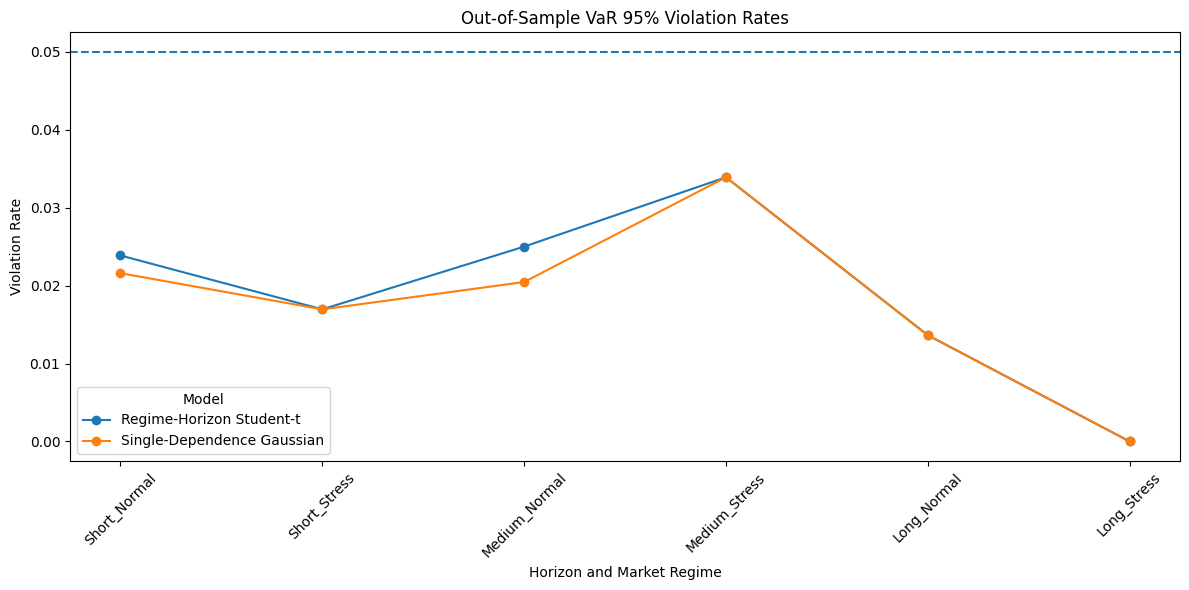

In [47]:
violation_95_table.plot(
    figsize=(12, 6),
    marker="o"
)

plt.axhline(
    0.05,
    linestyle="--",
    label="Expected 5%"
)

plt.title(
    "Out-of-Sample VaR 95% Violation Rates"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Violation Rate"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [48]:
violation_99_table = (
    oos_results.pivot(
        index="Dataset",
        columns="Model",
        values="Violation_Rate_99"
    )
)

violation_99_table = (
    violation_99_table
    .reindex(dataset_order)
)

violation_99_table

Model,Regime-Horizon Student-t,Single-Dependence Gaussian
Dataset,,
Short_Normal,0.001136,0.001136
Short_Stress,0.000000,0.000000
Medium_Normal,0.002273,0.002273
Medium_Stress,0.000000,0.000000
Long_Normal,0.003409,0.004545
Long_Stress,0.000000,0.000000


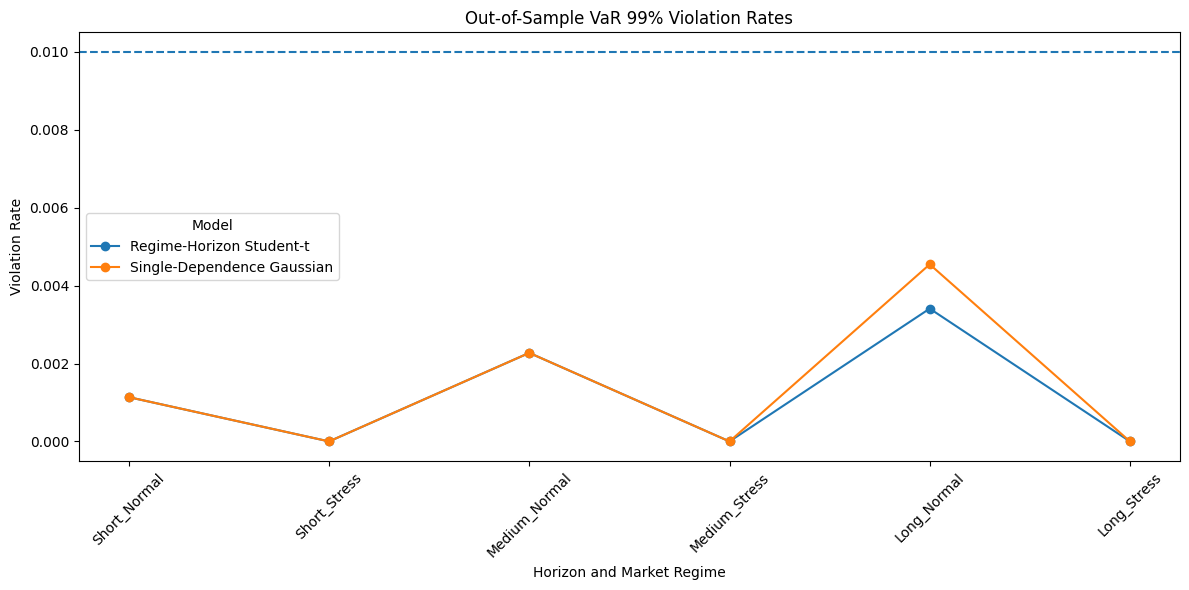

In [49]:
violation_99_table.plot(
    figsize=(12, 6),
    marker="o"
)

plt.axhline(
    0.01,
    linestyle="--",
    label="Expected 1%"
)

plt.title(
    "Out-of-Sample VaR 99% Violation Rates"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Violation Rate"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [50]:
average_calibration_95 = (
    oos_results
    .groupby("Model")[
        "Abs_Calibration_Error_95"
    ]
    .mean()
)

average_calibration_95

Model
Regime-Horizon Student-t      0.031109
Single-Dependence Gaussian    0.032245
Name: Abs_Calibration_Error_95, dtype: float64

In [51]:
average_calibration_99 = (
    oos_results
    .groupby("Model")[
        "Abs_Calibration_Error_99"
    ]
    .mean()
)

average_calibration_99

Model
Regime-Horizon Student-t      0.008864
Single-Dependence Gaussian    0.008674
Name: Abs_Calibration_Error_99, dtype: float64

In [52]:
oos_es = oos_results.pivot(
    index="Dataset",
    columns="Model",
    values="ES_97.5"
)

oos_es = oos_es.reindex(
    dataset_order
)

oos_es

Model,Regime-Horizon Student-t,Single-Dependence Gaussian
Dataset,,
Short_Normal,0.029576,0.029064
Short_Stress,0.037193,0.032613
Medium_Normal,0.012875,0.013279
Medium_Stress,0.019060,0.016855
Long_Normal,0.006408,0.006252
Long_Stress,0.007592,0.006751


In [53]:
oos_es[
    "Risk_Difference"
] = (
    oos_es[
        "Regime-Horizon Student-t"
    ]
    -
    oos_es[
        "Single-Dependence Gaussian"
    ]
)

oos_es[
    "Risk_Difference_Percent"
] = (
    oos_es[
        "Risk_Difference"
    ]
    /
    oos_es[
        "Regime-Horizon Student-t"
    ]
    * 100
)

oos_es

Model,Regime-Horizon Student-t,Single-Dependence Gaussian,Risk_Difference,Risk_Difference_Percent
Dataset,,,,
Short_Normal,0.029576,0.029064,0.000512,1.730531
Short_Stress,0.037193,0.032613,0.004580,12.313398
Medium_Normal,0.012875,0.013279,-0.000405,-3.145198
Medium_Stress,0.019060,0.016855,0.002204,11.565562
Long_Normal,0.006408,0.006252,0.000156,2.427626
Long_Stress,0.007592,0.006751,0.000841,11.077009


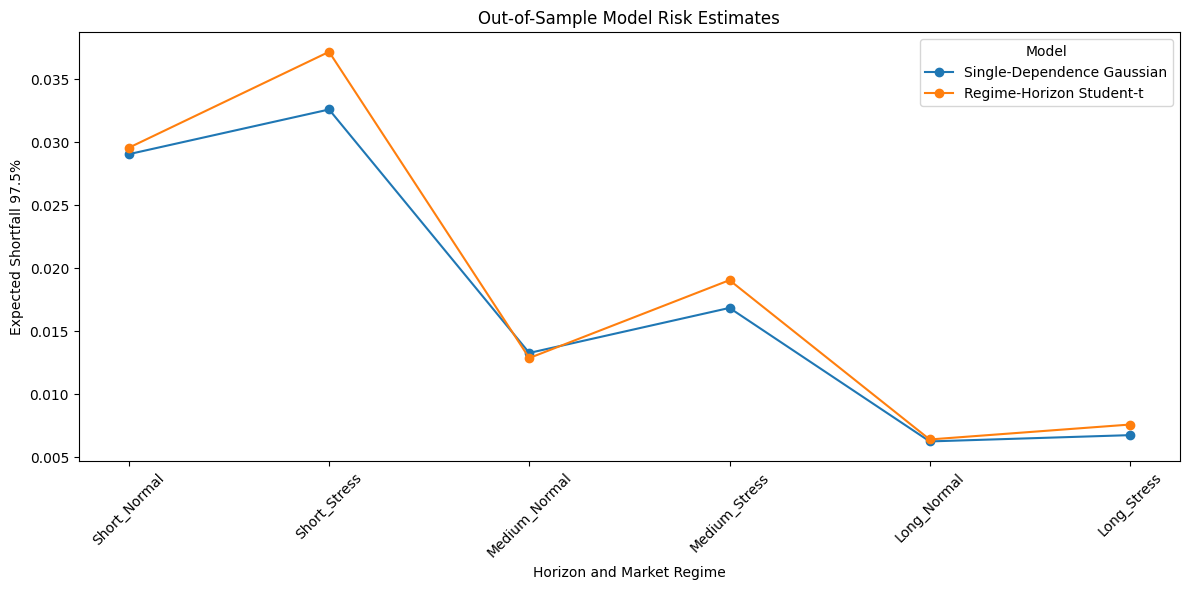

In [54]:
oos_es[
    [
        "Single-Dependence Gaussian",
        "Regime-Horizon Student-t"
    ]
].plot(
    figsize=(12, 6),
    marker="o"
)

plt.title(
    "Out-of-Sample Model Risk Estimates"
)

plt.xlabel(
    "Horizon and Market Regime"
)

plt.ylabel(
    "Expected Shortfall 97.5%"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [55]:
oos_results.to_csv(
    "outputs/tables/out_of_sample_results.csv",
    index=False
)

In [56]:
violation_95_table.to_csv(
    "outputs/tables/oos_var95_violation_rates.csv"
)

In [57]:
violation_99_table.to_csv(
    "outputs/tables/oos_var99_violation_rates.csv"
)

In [58]:
oos_es.to_csv(
    "outputs/tables/oos_expected_shortfall_comparison.csv"
)

In [59]:
for name, actual_returns in (
    actual_test_portfolios.items()
):

    output = pd.DataFrame({
        "Portfolio_Return":
        actual_returns
    })

    output.to_csv(
        f"outputs/tables/test_returns_{name}.csv",
        index=False
    )

In [60]:
print(
    "Notebook 09 completed successfully."
)

print(
    "\nOut-of-sample results:"
)

display(
    display_results.round(3)
)

print(
    "\nAverage 95% calibration error:"
)

display(
    average_calibration_95
)

print(
    "\nAverage 99% calibration error:"
)

display(
    average_calibration_99
)

print(
    "\nExpected Shortfall model differences:"
)

display(
    oos_es.round(4)
)

Notebook 09 completed successfully.

Out-of-sample results:


,Dataset,Model,VaR_95,VaR_99,ES_97.5,Violations_95,Violation_Rate_95,Violations_99,Violation_Rate_99,Test_N,nu,Expected_Rate_95,Expected_Rate_99,Violation_Error_95,Violation_Error_99,Abs_Calibration_Error_95,Abs_Calibration_Error_99
0,Short_Normal,Single-Dependence Gaussian,1.689,2.849,2.906,19,2.159,1,0.114,880,NaN,0.05,0.01,-0.028,-0.009,2.841,0.886
1,Short_Normal,Regime-Horizon Student-t,1.651,2.883,2.958,21,2.386,1,0.114,880,13.0,0.05,0.01,-0.026,-0.009,2.614,0.886
2,Short_Stress,Single-Dependence Gaussian,1.836,3.108,3.261,1,1.695,0,0.000,59,NaN,0.05,0.01,-0.033,-0.010,3.305,1.000
3,Short_Stress,Regime-Horizon Student-t,1.842,3.390,3.719,1,1.695,0,0.000,59,5.0,0.05,0.01,-0.033,-0.010,3.305,1.000
4,Medium_Normal,Single-Dependence Gaussian,0.864,1.351,1.328,18,2.045,2,0.227,880,NaN,0.05,0.01,-0.030,-0.008,2.955,0.773
5,Medium_Normal,Regime-Horizon Student-t,0.817,1.268,1.287,22,2.500,2,0.227,880,12.0,0.05,0.01,-0.025,-0.008,2.500,0.773
6,Medium_Stress,Single-Dependence Gaussian,0.983,1.695,1.686,2,3.390,0,0.000,59,NaN,0.05,0.01,-0.016,-0.010,1.610,1.000
7,Medium_Stress,Regime-Horizon Student-t,1.040,1.892,1.906,2,3.390,0,0.000,59,4.0,0.05,0.01,-0.016,-0.010,1.610,1.000
8,Long_Normal,Single-Dependence Gaussian,0.449,0.623,0.625,12,1.364,4,0.455,880,NaN,0.05,0.01,-0.036,-0.005,3.636,0.545
9,Long_Normal,Regime-Horizon Student-t,0.453,0.630,0.641,12,1.364,3,0.341,880,10.0,0.05,0.01,-0.036,-0.007,3.636,0.659



Average 95% calibration error:


Model
Regime-Horizon Student-t      0.031109
Single-Dependence Gaussian    0.032245
Name: Abs_Calibration_Error_95, dtype: float64


Average 99% calibration error:


Model
Regime-Horizon Student-t      0.008864
Single-Dependence Gaussian    0.008674
Name: Abs_Calibration_Error_99, dtype: float64


Expected Shortfall model differences:


Model,Regime-Horizon Student-t,Single-Dependence Gaussian,Risk_Difference,Risk_Difference_Percent
Dataset,,,,
Short_Normal,0.0296,0.0291,0.0005,1.7305
Short_Stress,0.0372,0.0326,0.0046,12.3134
Medium_Normal,0.0129,0.0133,-0.0004,-3.1452
Medium_Stress,0.0191,0.0169,0.0022,11.5656
Long_Normal,0.0064,0.0063,0.0002,2.4276
Long_Stress,0.0076,0.0068,0.0008,11.0770
